Пункт 2-3: Загрузка и подготовка данных
Размерность X train: (60000, 28, 28)
Размерность y train: (60000,)
Размерность X test:  (10000, 28, 28)
Размерность y test:  (10000,)

Пункт 4: Визуализация первых 4 элементов обучающей выборки
Элемент [0]: истинная метка = 8
Элемент [1]: истинная метка = 9
Элемент [2]: истинная метка = 6
Элемент [3]: истинная метка = 6


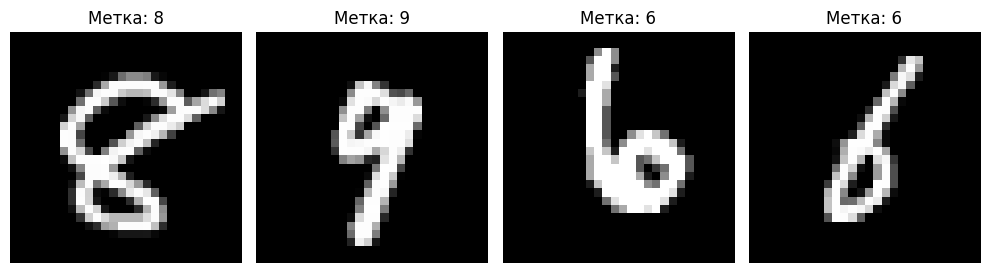


--- Размерности после предобработки ---
Обучающие выборки (X_train_ready): (60000, 784)
Обучающие метки (y_train_ready):  (60000, 10)
Тестовые выборки (X_test_ready):  (10000, 784)
Тестовые метки (y_test_ready):  (10000, 10)

Пункт 6-7: Реализация однослойной сети (0 скрытых слоев)

--- Архитектура сети (0 скрытых слоев) ---


Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_19 (Dense)                │ (None, 10)             │         7,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,850 (30.66 KB)

 Trainable params: 7,850 (30.66 KB)

 Non-trainable params: 0 (0.00 B)


--- Процесс обучения ---

Значение функции ошибки (Test Loss): 0.2921
Метрика качества (Test Accuracy): 0.9153 (91.53%)


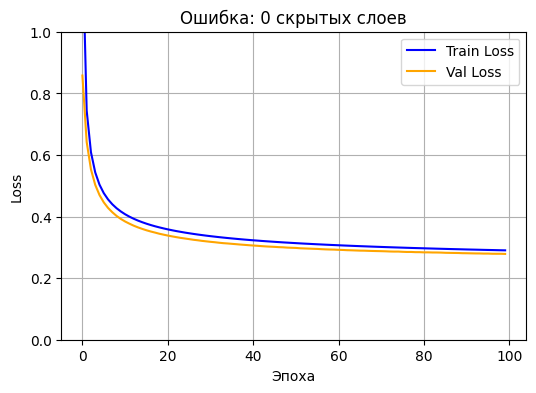


Пункт 8: Исследование 1 скрытого слоя (100, 300, 500, 1000 нейронов)

---> Обучение модели с 1 скрытым слоем (100 нейронов)...
Результат для 100 нейронов -> Test Loss: 0.2552, Test Accuracy: 0.9250 (92.50%)


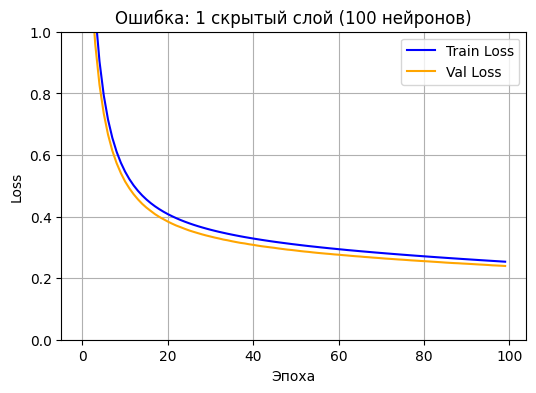


---> Обучение модели с 1 скрытым слоем (300 нейронов)...
Результат для 300 нейронов -> Test Loss: 0.2741, Test Accuracy: 0.9187 (91.87%)


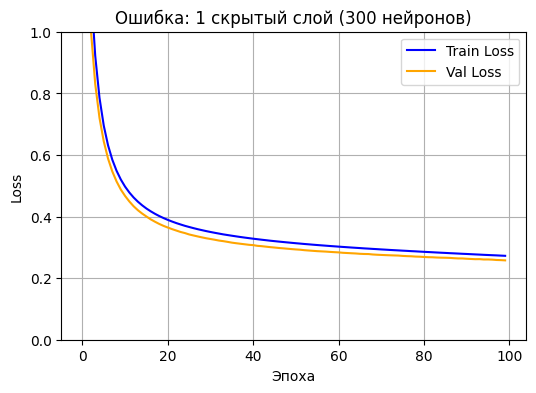


---> Обучение модели с 1 скрытым слоем (500 нейронов)...
Результат для 500 нейронов -> Test Loss: 0.2808, Test Accuracy: 0.9176 (91.76%)


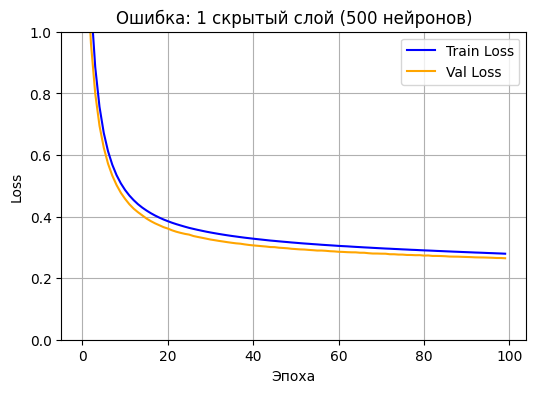


---> Обучение модели с 1 скрытым слоем (1000 нейронов)...
Результат для 1000 нейронов -> Test Loss: 0.2863, Test Accuracy: 0.9159 (91.59%)


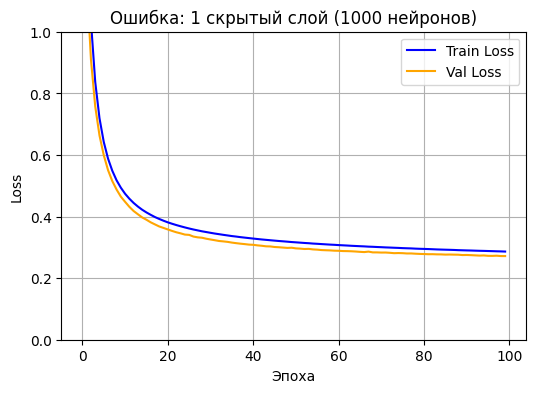


[ВЫВОД ПО П.8]: Наилучшее количество нейронов в 1-м скрытом слое: 100 (Accuracy: 92.50%)

Пункт 9: Добавление второго скрытого слоя (50, 100, 300 нейронов)
Фиксируем 1-й слой на лучшем значении из п.8: 100 нейронов

---> Обучение модели со 2-м скрытым слоем (50 нейронов)...
Результат для 2-го слоя из 50 нейронов -> Test Loss: 0.2751, Test Accuracy: 0.9197 (91.97%)


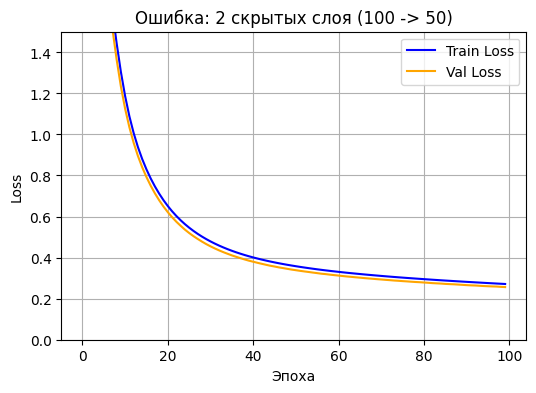


---> Обучение модели со 2-м скрытым слоем (100 нейронов)...
Результат для 2-го слоя из 100 нейронов -> Test Loss: 0.2717, Test Accuracy: 0.9185 (91.85%)


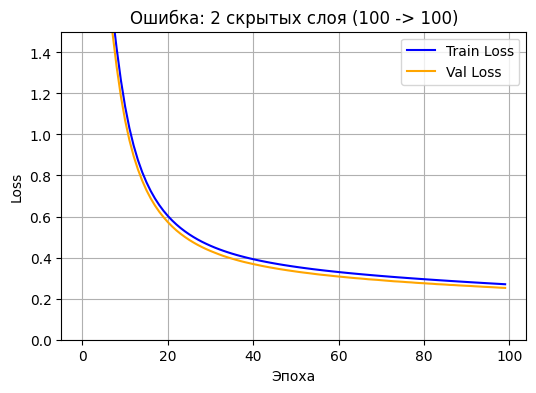


---> Обучение модели со 2-м скрытым слоем (300 нейронов)...
Результат для 2-го слоя из 300 нейронов -> Test Loss: 0.2668, Test Accuracy: 0.9202 (92.02%)


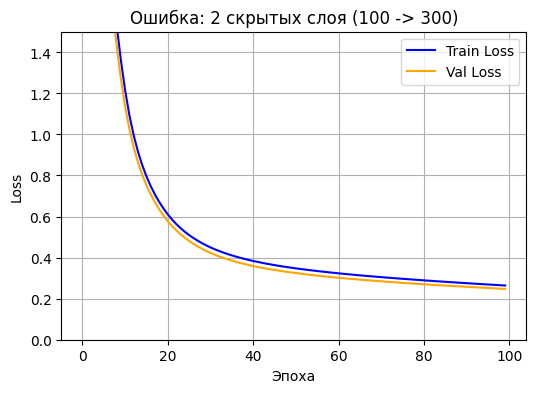


[ИТОГ ИССЛЕДОВАНИЯ]: Наилучшая архитектура: 1 скрытый слой (100 нейронов) с Accuracy: 92.50%

Пункт 10: Сводная таблица результатов исследования
Кол-во слоев    | Нейронов в 1-м  | Нейронов во 2-м | Accuracy    
--------------------------------------------------------------------
0               | -               | -               | 0.9153 (91.53%)
1               | 100             | -               | 0.9250 (92.50%)
1               | 300             | -               | 0.9187 (91.87%)
1               | 500             | -               | 0.9176 (91.76%)
1               | 1000            | -               | 0.9159 (91.59%)
2               | 100             | 50              | 0.9197 (91.97%)
2               | 100             | 100             | 0.9185 (91.85%)
2               | 100             | 300             | 0.9202 (92.02%)

Пункт 11: Тестирование лучшей архитектуры на двух случайных кадрах


In [ ]:
# ==============================================================================
# ЛАБОРАТОРНАЯ РАБОТА №1
# «Архитектура и обучение глубоких нейронных сетей»
# Вариант: k = 3 (random_state = 11)
# ==============================================================================

# --- ПУНКТ 1: Импорт модулей ---
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
import numpy as np
import sklearn
from keras.datasets import mnist
from sklearn.model_selection import train_test_split
from PIL import Image, ImageDraw

# --- ПУНКТ 2-3: Загрузка и разбиение датасета MNIST ---
print("==================================================")
print("Пункт 2-3: Загрузка и подготовка данных")
print("==================================================")
(X_train_raw, y_train_raw), (X_test_raw, y_test_raw) = mnist.load_data()

# Объединяем в один набор для кастомного разделения
X_all = np.concatenate((X_train_raw, X_test_raw))
y_all = np.concatenate((y_train_raw, y_test_raw))

# Разбиение по варианту k=3 (random_state = 4*3 - 1 = 11)
X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all,
    test_size=10000,
    train_size=60000,
    random_state=11
)

print('Размерность X train:', X_train.shape)
print('Размерность y train:', y_train.shape)
print('Размерность X test: ', X_test.shape)
print('Размерность y test: ', y_test.shape)

# --- ПУНКТ 4: Вывод первых 4 элементов обучающих данных ---
print("\n==================================================")
print("Пункт 4: Визуализация первых 4 элементов обучающей выборки")
print("==================================================")
fig, axes = plt.subplots(1, 4, figsize=(10, 3))
for i in range(4):
    axes[i].imshow(X_train[i], cmap=plt.get_cmap('gray'))
    axes[i].set_title(label=f"Метка: {y_train[i]}")
    axes[i].axis('off')
    print(f"Элемент [{i}]: истинная метка = {y_train[i]}")
plt.tight_layout()
plt.show()

# --- ПУНКТ 5: Предобработка данных ---
# Изменение формы (Reshape) в плоские векторы (размер 784)
X_train_flat = X_train.reshape(X_train.shape[0], 28 * 28).astype('float32')
X_test_flat = X_test.reshape(X_test.shape[0], 28 * 28).astype('float32')

# Нормализация данных (приведение к диапазону 0.0 - 1.0)
X_train_ready = X_train_flat / 255.0
X_test_ready = X_test_flat / 255.0

# One-Hot Encoding для меток
y_train_ready = keras.utils.to_categorical(y_train, num_classes=10)
y_test_ready = keras.utils.to_categorical(y_test, num_classes=10)

print("\n--- Размерности после предобработки ---")
print("Обучающие выборки (X_train_ready):", X_train_ready.shape)
print("Обучающие метки (y_train_ready): ", y_train_ready.shape)
print("Тестовые выборки (X_test_ready): ", X_test_ready.shape)
print("Тестовые метки (y_test_ready): ", y_test_ready.shape)

# Переменные для сбора статистики (Пункт 10) и поиска лучшей модели
results_table = []
absolute_best_acc = 0.0
best_model = None
best_config_name = ""

# --- ПУНКТ 6-7: Однослойная сеть (0 скрытых слоев) ---
print("\n==================================================")
print("Пункт 6-7: Реализация однослойной сети (0 скрытых слоев)")
print("==================================================")

model_0 = keras.Sequential([
    keras.layers.Dense(10, activation='softmax', input_shape=(784,))
])

model_0.compile(optimizer='sgd', loss='categorical_crossentropy', metrics=['accuracy'])
print("\n--- Архитектура сети (0 скрытых слоев) ---")
model_0.summary()

print("\n--- Процесс обучения ---")
history_0 = model_0.fit(
    X_train_ready, y_train_ready,
    epochs=100,
    batch_size=128,
    validation_split=0.1,
    verbose=0 # Скрываем логи эпох для чистоты вывода
)

# Оценка на тестовых данных
test_results_0 = model_0.evaluate(X_test_ready, y_test_ready, verbose=0)
print(f"\nЗначение функции ошибки (Test Loss): {test_results_0[0]:.4f}")
print(f"Метрика качества (Test Accuracy): {test_results_0[1]:.4f} ({test_results_0[1]*100:.2f}%)")

# Добавление в сводные данные
results_table.append({"layers": 0, "n1": "-", "n2": "-", "accuracy": test_results_0[1]})
if test_results_0[1] > absolute_best_acc:
    absolute_best_acc = test_results_0[1]
    best_model = model_0
    best_config_name = "0 скрытых слоев"

# График функции ошибки для 0 скрытых слоев
plt.figure(figsize=(6, 4))
plt.plot(history_0.history['loss'], label='Train Loss', color='blue')
plt.plot(history_0.history['val_loss'], label='Val Loss', color='orange')
plt.title('Ошибка: 0 скрытых слоев')
plt.xlabel('Эпоха')
plt.ylabel('Loss')
plt.ylim(0, 1.0)
plt.grid(True)
plt.legend()
plt.show()

# --- ПУНКТ 8: Исследование 1 скрытого слоя (функция sigmoid) ---
print("\n==================================================")
print("Пункт 8: Исследование 1 скрытого слоя (100, 300, 500, 1000 нейронов)")
print("==================================================")

neurons_1st_layer = [100, 300, 500, 1000]
best_accuracy_1st = 0.0
best_neurons_1st = None

for n_hidden in neurons_1st_layer:
    print(f"\n---> Обучение модели с 1 скрытым слоем ({n_hidden} нейронов)...")

    model_1 = keras.Sequential([
        keras.layers.Dense(n_hidden, activation='sigmoid', input_shape=(784,)),
        keras.layers.Dense(10, activation='softmax')
    ])

    model_1.compile(optimizer='sgd', loss='categorical_crossentropy', metrics=['accuracy'])

    history_1 = model_1.fit(X_train_ready, y_train_ready, epochs=100, batch_size=128, validation_split=0.1, verbose=0)
    test_loss, test_acc = model_1.evaluate(X_test_ready, y_test_ready, verbose=0)

    print(f"Результат для {n_hidden} нейронов -> Test Loss: {test_loss:.4f}, Test Accuracy: {test_acc:.4f} ({test_acc*100:.2f}%)")

    # Сохраняем в общую таблицу
    results_table.append({"layers": 1, "n1": n_hidden, "n2": "-", "accuracy": test_acc})

    # Ищем лучшую конфигурацию для шага 8
    if test_acc > best_accuracy_1st:
        best_accuracy_1st = test_acc
        best_neurons_1st = n_hidden

    # Проверяем на глобальный максимум точности
    if test_acc > absolute_best_acc:
        absolute_best_acc = test_acc
        best_model = model_1
        best_config_name = f"1 скрытый слой ({n_hidden} нейронов)"

    # Строим графики для КАЖДОГО варианта
    plt.figure(figsize=(6, 4))
    plt.plot(history_1.history['loss'], label='Train Loss', color='blue')
    plt.plot(history_1.history['val_loss'], label='Val Loss', color='orange')
    plt.title(f'Ошибка: 1 скрытый слой ({n_hidden} нейронов)')
    plt.xlabel('Эпоха')
    plt.ylabel('Loss')
    plt.ylim(0, 1.0)
    plt.grid(True)
    plt.legend()
    plt.show()

print(f"\n[ВЫВОД ПО П.8]: Наилучшее количество нейронов в 1-м скрытом слое: {best_neurons_1st} (Accuracy: {best_accuracy_1st*100:.2f}%)")

# --- ПУНКТ 9: Добавление второго скрытого слоя (функция sigmoid) ---
print("\n==================================================")
print("Пункт 9: Добавление второго скрытого слоя (50, 100, 300 нейронов)")
print(f"Фиксируем 1-й слой на лучшем значении из п.8: {best_neurons_1st} нейронов")
print("==================================================")

neurons_2nd_layer = [50, 100, 300]

for n_hidden_2 in neurons_2nd_layer:
    print(f"\n---> Обучение модели со 2-м скрытым слоем ({n_hidden_2} нейронов)...")

    model_2 = keras.Sequential([
        keras.layers.Dense(best_neurons_1st, activation='sigmoid', input_shape=(784,)),
        keras.layers.Dense(n_hidden_2, activation='sigmoid'),
        keras.layers.Dense(10, activation='softmax')
    ])

    model_2.compile(optimizer='sgd', loss='categorical_crossentropy', metrics=['accuracy'])

    history_2 = model_2.fit(X_train_ready, y_train_ready, epochs=100, batch_size=128, validation_split=0.1, verbose=0)
    test_loss_2, test_acc_2 = model_2.evaluate(X_test_ready, y_test_ready, verbose=0)

    print(f"Результат для 2-го слоя из {n_hidden_2} нейронов -> Test Loss: {test_loss_2:.4f}, Test Accuracy: {test_acc_2:.4f} ({test_acc_2*100:.2f}%)")

    # Сохраняем в общую таблицу
    results_table.append({"layers": 2, "n1": best_neurons_1st, "n2": n_hidden_2, "accuracy": test_acc_2})

    # Проверяем на глобальный максимум точности
    if test_acc_2 > absolute_best_acc:
        absolute_best_acc = test_acc_2
        best_model = model_2
        best_config_name = f"2 скрытых слоя ({best_neurons_1st} -> {n_hidden_2})"

    # Строим графики для каждого варианта
    plt.figure(figsize=(6, 4))
    plt.plot(history_2.history['loss'], label='Train Loss', color='blue')
    plt.plot(history_2.history['val_loss'], label='Val Loss', color='orange')
    plt.title(f'Ошибка: 2 скрытых слоя ({best_neurons_1st} -> {n_hidden_2})')
    plt.xlabel('Эпоха')
    plt.ylabel('Loss')
    plt.ylim(0, 1.5)
    plt.grid(True)
    plt.legend()
    plt.show()

print(f"\n[ИТОГ ИССЛЕДОВАНИЯ]: Наилучшая архитектура: {best_config_name} с Accuracy: {absolute_best_acc*100:.2f}%")

# --- ПУНКТ 10: Вывод сводной таблицы результатов исследования ---
print("\n==================================================")
print("Пункт 10: Сводная таблица результатов исследования")
print("==================================================")
print(f"{'Кол-во слоев':<15} | {'Нейронов в 1-м':<15} | {'Нейронов во 2-м':<15} | {'Accuracy':<12}")
print("-" * 68)
for row in results_table:
    acc_format = f"{row['accuracy']:.4f} ({row['accuracy']*100:.2f}%)"
    print(f"{row['layers']:<15} | {str(row['n1']):<15} | {str(row['n2']):<15} | {acc_format:<12}")

# --- ПУНКТ 11: Распознавание двух тестовых изображений наилучшей сетью ---
print("\n==================================================")
print("Пункт 11: Тестирование лучшей архитектуры на двух случайных кадрах")
print("==================================================")
for i in range(2):
    img = X_test[i]
    true_label = y_test[i]

    img_ready = img.reshape(1, 28 * 28).astype('float32') / 255.0


Подготовка графики...

Пункт 11: Распознавание двух тестовых изображений


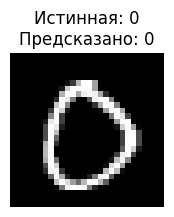

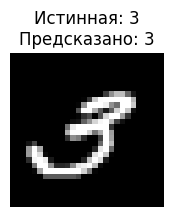


Пункт 12-13: Эксперимент с собственной цифрой 3


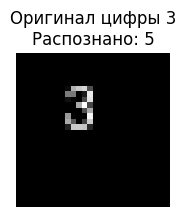

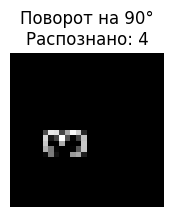

In [ ]:
# --- ПРИНУДИТЕЛЬНЫЙ ВЫВОД КАРТИНОК ДЛЯ ПУНКТОВ 11, 12, 13 ---
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, ImageDraw

# 1. Создаем наилучшую модель по результатам п.10 (1 слой, 100 нейронов)
fast_best_model = keras.Sequential([
    keras.layers.Dense(100, activation='sigmoid', input_shape=(784,)),
    keras.layers.Dense(10, activation='softmax')
])
fast_best_model.compile(optimizer='sgd', loss='categorical_crossentropy', metrics=['accuracy'])

# Быстрое обучение (всего 5 эпох, чтобы просто появились картинки)
print("Подготовка графики...")
fast_best_model.fit(X_train_ready, y_train_ready, epochs=5, batch_size=128, verbose=0)

# --- ПУНКТ 11: Два случайных кадра из теста ---
print("\n==================================================")
print("Пункт 11: Распознавание двух тестовых изображений")
print("==================================================")
for i in range(2):
    img = X_test[i]
    true_label = y_test[i]
    img_ready = img.reshape(1, 28 * 28).astype('float32') / 255.0
    pred = fast_best_model.predict(img_ready, verbose=0)

    plt.figure(figsize=(2, 2))
    plt.imshow(img, cmap='gray')
    plt.title(f"Истинная: {true_label}\nПредсказано: {np.argmax(pred)}")
    plt.axis('off')
    plt.show()

# --- ПУНКТ 12-13: Создание и поворот тройки ---
print("\n==================================================")
print("Пункт 12-13: Эксперимент с собственной цифрой 3")
print("==================================================")
img_custom = Image.new('L', (28, 28), color=0)
draw = ImageDraw.Draw(img_custom)
draw.text((9, 4), "3", fill=255)
X_custom = np.array(img_custom)

# Вывод оригинала
pred_orig = fast_best_model.predict(X_custom.reshape(1, 28 * 28).astype('float32') / 255.0, verbose=0)
plt.figure(figsize=(2, 2))
plt.imshow(X_custom, cmap='gray')
plt.title(f"Оригинал цифры 3\nРаспознано: {np.argmax(pred_orig)}")
plt.axis('off')
plt.show()

# Вывод повернутой
X_custom_rotated = np.rot90(X_custom, k=1)
pred_rot = fast_best_model.predict(X_custom_rotated.reshape(1, 28 * 28).astype('float32') / 255.0, verbose=0)
plt.figure(figsize=(2, 2))
plt.imshow(X_custom_rotated, cmap='gray')
plt.title(f"Поворот на 90°\nРаспознано: {np.argmax(pred_rot)}")
plt.axis('off')
plt.show()